# Análisis de datos exploratorio
En el presente notebook se presenta el análisis de datos exploratorio(EDA) de los datos de mibici. Este se hace con el objetivo de entender los datos que se utilizarán para responder las preguntas de negocio, con este análisis se espera encontrar hallazgos interesantes sobre las relaciones de los datos que permitan tomar acciones con ellos que repercutan en el desarrollo de nuestros modelos de aprendizaje automático.

In [1]:
# importacion de librerias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

A continuacion se presenta la carga y unión de los archivos que se utilizarán para el proyecto, dado que los registros están disponibles para cada mes, se hace la carga de los archivos y su concatenación en un dataframe final para poder hacer un análisis que abarque los meses que planeamos utilizar

In [2]:
fechas = pd.date_range(start="2024-10-01", end="2026-09-01", freq="MS")

dfs = []
folder_path = Path("../data/external")

for fecha in fechas:
    year_month = fecha.strftime("%Y_%m")
    file_name = f"datos_abiertos_{year_month}.csv"
    file_path = folder_path / file_name

    if file_path.exists():
        # Probamos encodings diferentes 
        try:
            df_temp = pd.read_csv(file_path, encoding="utf-8")
        except UnicodeDecodeError:
            df_temp = pd.read_csv(file_path, encoding="latin-1")

        # Se eliminan comillas innecesarias
        df_temp.columns = df_temp.columns.str.replace('"', "").str.strip()

        # Corregimos nombres de columnas corruptos
        df_temp = df_temp.rename(
            columns={
                "Ao_de_nacimiento": "Año_de_nacimiento",
                "A%C3%B1o_de_nacimiento": "Año_de_nacimiento",
            }
        )

        dfs.append(df_temp)
    else:
        print(f"Archivo no encontrado: {file_name}")

# Concatenar todos los meses en un solo DataFrame
df_viajes = pd.concat(dfs, ignore_index=True)

print(f"Total de registros cargados: {len(df_viajes):,}")

Total de registros cargados: 9,043,925


Se incluye la nomenclatura dentro del DataFrame que ya se está utilizando para tener una mejor interpretabilidad de los datos que estamos manejando

In [3]:
# Nomenclatura
df_nomenclatura = pd.read_csv(
    folder_path / "nomenclatura_2026_09.csv", encoding="utf-8"
)
df_nomenclatura.columns = df_nomenclatura.columns.str.replace('"', "").str.strip()

# Cruce origen
df_analisis = df_viajes.merge(
    df_nomenclatura.add_prefix("origen_"),
    left_on="Origen_Id",
    right_on="origen_id",
    how="left",
)

# Cruce destino
df_analisis = df_analisis.merge(
    df_nomenclatura.add_prefix("destino_"),
    left_on="Destino_Id",
    right_on="destino_id",
    how="left",
)

Revision general de tipos de datos

In [4]:
df_analisis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9043925 entries, 0 to 9043924
Data columns (total 18 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Viaje_Id            int64  
 1   Usuario_Id          int64  
 2   Genero              object 
 3   Año_de_nacimiento   float64
 4   Inicio_del_viaje    object 
 5   Fin_del_viaje       object 
 6   Origen_Id           int64  
 7   Destino_Id          int64  
 8   origen_id           float64
 9   origen_name         object 
 10  origen_latitude     float64
 11  origen_longitude    float64
 12  origen_dpcapacity   float64
 13  destino_id          float64
 14  destino_name        object 
 15  destino_latitude    float64
 16  destino_longitude   float64
 17  destino_dpcapacity  float64
dtypes: float64(9), int64(4), object(5)
memory usage: 1.2+ GB


In [5]:
df_analisis.isnull().sum()

Viaje_Id                  0
Usuario_Id                0
Genero                71275
Año_de_nacimiento      1928
Inicio_del_viaje          0
Fin_del_viaje             0
Origen_Id                 0
Destino_Id                0
origen_id              1960
origen_name            1960
origen_latitude        1960
origen_longitude       1960
origen_dpcapacity      1960
destino_id             2123
destino_name           2123
destino_latitude       2123
destino_longitude      2123
destino_dpcapacity     2123
dtype: int64

Inicio_del_viaje y Fin_del_viaje son objetos, por lo que vamos a hacer cambio de tipo para que sean datetime, ademas despues de este cambio podemos sacar una nueva columna que sea duracion del viaje. Podemos notar que nos quedamos origen_id y destino_id repetidos por lo que vamos a eliminar las columnas redundantes para quedarnos unicamente con las originales. Ademas podriamos obtener una nueva columna que indique si el origen y destino son el mismo, esto podria ser un indicador del tipo de uso que se le dio a la bicicleta, quizas fue enteramente recreacional si se devolvió al mismo lugar de origen.

Encontramos también que hay varios registros nulos, sin embargo, no representan ni el 1% de los datos que tenemos por lo que si se decide eliminarlos no generarían una gran pérdida mientras se encuentren distribuidos entre todos los meses. Se puede notar tambien que han habido cambios en las estaciones dado que tenemos registros faltantes en la union que hicimos en las nomenclaturas donde vemos ausencia de datos, lo que indica que ciertas estaciones no estaban entre nuestros datos.

In [6]:
# Datetime
df_analisis["Inicio_del_viaje"] = pd.to_datetime(df_analisis["Inicio_del_viaje"], dayfirst=True, format="mixed", errors="coerce")
df_analisis["Fin_del_viaje"] = pd.to_datetime(df_analisis["Fin_del_viaje"], dayfirst=True, format="mixed", errors="coerce")


# Eliminacion de columnas redundantes traídas por el merge
df_analisis.drop(columns=["origen_id", "origen_id"], axis=1, inplace=True)

# Mapeo de tipos de datos para optimizacion de RAM
dtypes_optimizados = {
    # Categóricos
    "Genero": "category",
    "origen_name": "category",
    "destino_name": "category",
    # Ints
    "Usuario_Id": "int32",
    "Origen_Id": "int16",
    "Destino_Id": "int16",
    "Año_de_nacimiento": "Int16",
    "origen_dpcapacity": "Int16",
    "destino_dpcapacity": "Int16",
    # Floats
    "origen_latitude": "float32",
    "origen_longitude": "float32",
    "destino_latitude": "float32",
    "destino_longitude": "float32",
}
# Aplicar los tipos
df_analisis = df_analisis.astype(dtypes_optimizados)

In [9]:
# Duración del viaje en minutos
df_analisis["duracion_minutos"] = (
    df_analisis["Fin_del_viaje"] - df_analisis["Inicio_del_viaje"]
).dt.total_seconds() / 60

# Componentes temporales
df_analisis["hora_inicio"] = df_analisis["Inicio_del_viaje"].dt.hour.astype(
    "int8"
)
df_analisis["dia_semana"] = df_analisis[
    "Inicio_del_viaje"
].dt.day_name()  # o .dt.dayofweek
df_analisis["mes_año"] = df_analisis["Inicio_del_viaje"].dt.to_period("M")

# Mismo origen - destino
df_analisis["Origen=Destino"] = df_analisis['Origen_Id'] == df_analisis['Destino_Id']

df_analisis["es_fin_de_semana"] = df_analisis["Inicio_del_viaje"].dt.dayofweek >= 5


df_analisis["edad"] = df_analisis["Inicio_del_viaje"].dt.year - df_analisis["Año_de_nacimiento"]

Dado que ya ha hecho la limpieza de datos y se han generado nuevas columnas de datos, se pasará a hacer un análisis de datos

In [10]:
df_analisis.describe()

,Viaje_Id,Usuario_Id,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,origen_latitude,origen_longitude,origen_dpcapacity,destino_id,destino_latitude,destino_longitude,destino_dpcapacity,duracion_minutos,hora_inicio,edad
count,9.043925e+06,9.043925e+06,9041997.0,9043925,9043925,9.043925e+06,9.043925e+06,9.041965e+06,9.041965e+06,9041965.0,9.041802e+06,9.041802e+06,9.041802e+06,9041802.0,9.043925e+06,9.043925e+06,9041997.0
mean,4.103777e+07,2.519317e+06,1990.417633,2025-10-01 06:24:51.876938496,2025-10-01 06:35:55.203244544,1.589498e+02,1.608003e+02,2.067944e+01,-1.033601e+02,18.247274,1.607425e+02,2.067991e+01,-1.033591e+02,18.453538,1.105544e+01,1.399990e+01,34.827047
min,3.584725e+07,1.020000e+02,199.0,2024-10-01 00:00:00,2024-10-01 00:08:00,2.000000e+00,2.000000e+00,2.063613e+01,-1.034332e+02,11.0,2.000000e+00,2.063613e+01,-1.034332e+02,11.0,0.000000e+00,0.000000e+00,1.0
25%,3.843577e+07,6.432410e+05,1985.0,2025-03-28 08:21:45,2025-03-28 08:32:21,5.100000e+01,5.100000e+01,2.067051e+01,-1.033724e+02,15.0,5.100000e+01,2.067092e+01,-1.033693e+02,15.0,5.766667e+00,1.000000e+01,27.0
50%,4.103258e+07,2.472507e+06,1993.0,2025-09-29 12:01:41,2025-09-29 12:11:35,1.570000e+02,1.570000e+02,2.067607e+01,-1.033585e+02,19.0,1.570000e+02,2.067634e+01,-1.033556e+02,19.0,9.466667e+00,1.400000e+01,32.0
75%,4.361192e+07,4.501247e+06,1999.0,2026-04-04 20:39:46,2026-04-04 20:58:49,2.600000e+02,2.650000e+02,2.068504e+01,-1.033481e+02,19.0,2.650000e+02,2.068586e+01,-1.033480e+02,19.0,1.483333e+01,1.800000e+01,41.0
max,4.625556e+07,5.006315e+06,2023.0,2026-09-30 23:59:48,2026-10-01 00:14:52,5.190000e+02,5.190000e+02,2.073952e+01,-1.032971e+02,39.0,5.190000e+02,2.073952e+01,-1.032971e+02,39.0,1.150077e+04,2.300000e+01,1827.0
std,3.007467e+06,1.744885e+06,15.388168,NaN,NaN,1.169580e+02,1.197057e+02,1.656075e-02,1.939611e-02,5.428502,1.196603e+02,1.645680e-02,1.854657e-02,5.572557,1.044033e+01,4.762126e+00,15.395261


Podemos notar anomalías en año de nacimiento con el año 199 y 2023. Estos se reflejan en la columna que generamos "Edad", donde encontramos 1827 y 1 año de edad; no existen personas con tantos años de edad, y no se puede usar el servicio si eres menor de 16 años. También encontramos que hay registros que contabilizan 0 minutos de uso y registros con 11500 horas, por lo que estos pueden ser limpiados.

In [11]:
# filtro para df
df = df_analisis[
    (df_analisis["duracion_minutos"] >= 1) & 
    (df_analisis["duracion_minutos"] <= 240) & # 4 horas de uso
    (df_analisis["edad"].between(16, 85) | df_analisis["edad"].isna()) # Edades entre las que puedes usar el servicio
].copy()

porcentaje_retenido = (len(df) / len(df_analisis)) * 100
print(f"Registros tras filtrado: {len(df):,} ({porcentaje_retenido:.2f}%)")

Registros tras filtrado: 8,769,740 (96.97%)


Contamos aún con 96.7% de datos que es un buen número realmente y nos quedamos con datos valiosos para su análisis

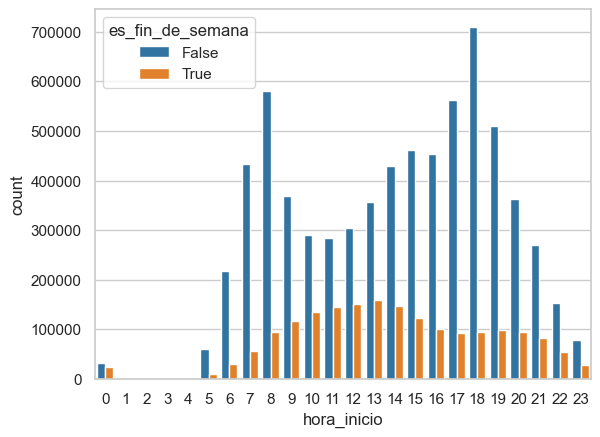

In [13]:
sns.countplot(
    data=df,
    x="hora_inicio",
    hue="es_fin_de_semana",
    palette={False: "#1f77b4", True: "#ff7f0e"},
)
plt.show()

Esta primera gráfica nos muestra la distribución de uso de las bicicletas en fin de semana y entre semana. Pareciera que el uso es mayor entre semana pero esto es porque hay más registros entre semana porque se cuentan 5 días contra 2, al ponerlo en perspectiva notamos que hay mucho uso de bicicletas en fin de semana y este ve más uso de 9 am a 15 pm.

C:\Users\aoran\AppData\Local\Temp\ipykernel_13640\1945904345.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


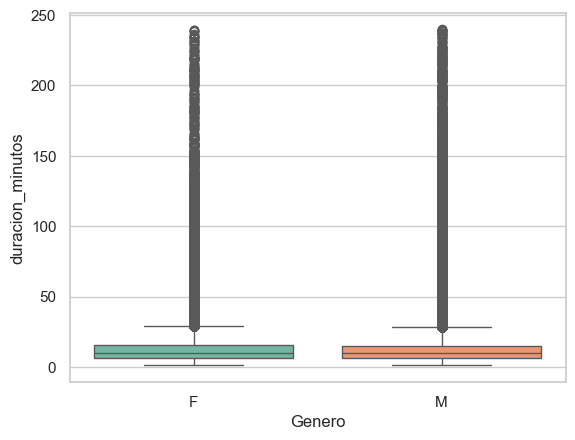

In [16]:
sns.boxplot(
    data=df,
    x="Genero",
    y="duracion_minutos",
    palette="Set2",
)
plt.show()

Esta gráfica nos muestra que realmente la gran mayoría de las personas usan menos de 50 minutos las bicicletas, por lo que se usan para viajes rápidos.

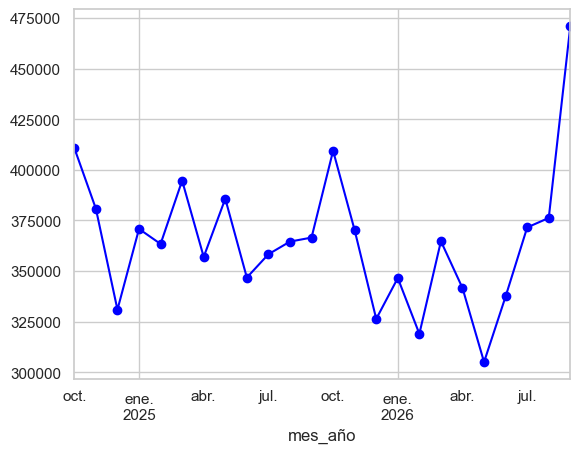

In [19]:
viajes_mensuales = df.groupby("mes_año").size()
viajes_mensuales.plot(kind="line", marker="o", color="blue")
plt.show()

Se puede notar una caída en el uso del servicio en el año 2026 junto con una alza en septiembre, registrando el mayor número de usos de los últimos años. También encontramos que en octubrede 2024 y 2025 hay un número de usos similar. Y en diciembre el uso del servicio baja, probablemente por el clima.

C:\Users\aoran\AppData\Local\Temp\ipykernel_13640\2381775308.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_rutas.values, y=top_rutas.index, palette="viridis")


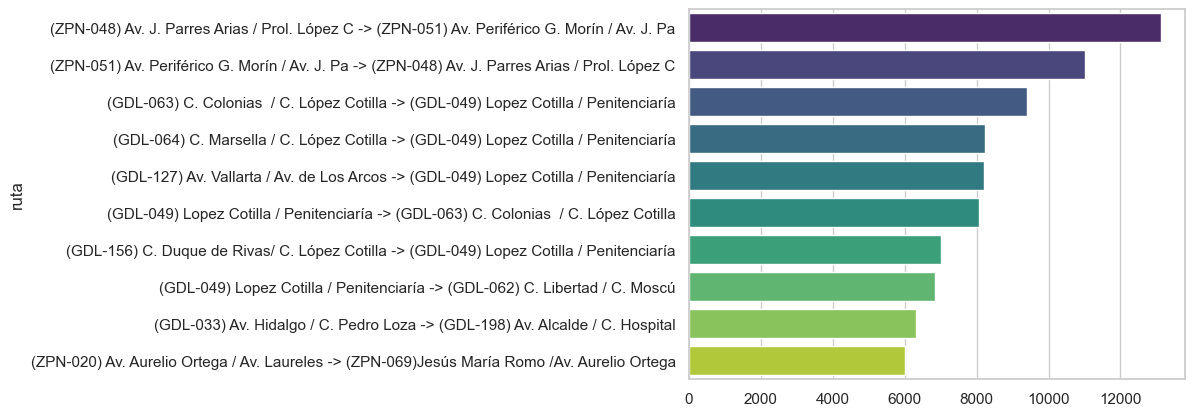

In [22]:
df["ruta"] = df["origen_name"].astype(str) + " -> " + df["destino_name"].astype(str)
top_rutas = df["ruta"].value_counts().head(10)
sns.barplot(x=top_rutas.values, y=top_rutas.index, palette="viridis")
plt.show()

Podemos ver las rutas más frecuentes.

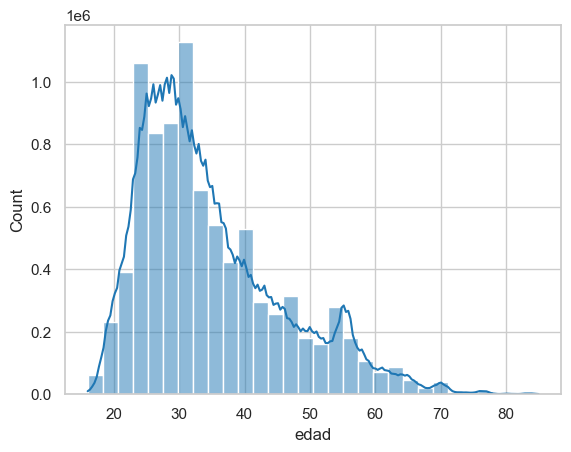

In [37]:
# --- GRÁFICA 1: Distribución de Edad ---
sns.histplot(
    data=df.dropna(subset=["edad"]),
    x="edad",
    bins=30,
    kde=True,
    color="#1f77b4"
)
plt.show()

El histograma nos muestra que la mayor parte de los usuarios del servicio se encuentran entre los 25 y 35 años. Podemos ver otros datos interesantes a continuación:

In [35]:
# Top 5 Estaciones de Origen y destino
print("--- TOP 5 ESTACIONES DE ORIGEN ---")
print(df["origen_name"].value_counts().head(5))
print("\n")

print("--- TOP 5 ESTACIONES DE DESTINO ---")
print(df["destino_name"].value_counts().head(5))
print("\n")

# Porcentaje de viajes realizados por usuarios recurrentes vs ocasionales
print("\n--- DISTRIBUCIÓN POR GÉNERO ---")
print(df["Genero"].value_counts(normalize=True) * 100)

--- TOP 5 ESTACIONES DE ORIGEN ---
origen_name
(GDL-049) Lopez Cotilla / Penitenciaría      178329
(GDL-033) Av. Hidalgo / C. Pedro Loza        144698
(GDL-198) Av. Alcalde / C. Hospital          133609
(GDL-009) Calz. Federalismo/ C. J. Angulo    127054
(GDL-050) C.Pedro Moreno /Federalismo        112445
Name: count, dtype: int64


--- TOP 5 ESTACIONES DE DESTINO ---
destino_name
(GDL-049) Lopez Cotilla / Penitenciaría          221692
(GDL-033) Av. Hidalgo / C. Pedro Loza            171583
(GDL-198) Av. Alcalde / C. Hospital              121206
(GDL-009) Calz. Federalismo/ C. J. Angulo        117484
(GDL-048) C. Constancio Hernández/ Av. Juaréz    109467
Name: count, dtype: int64



--- DISTRIBUCIÓN POR GÉNERO ---
Genero
M    72.553141
F    27.446859
Name: proportion, dtype: float64


Las 4 estaciones de origen y destino más frecuentadas se repiten en el mismo orden

Se obtuvieron datos interesantes a partir de los cuales vamos a desarrollar más las siguientes etapas de nuestro proyecto como feature engineering y desarrollo de modelos de Machine Learning